# How the Grover winner detector works

Tic-tac-toe has 8 winning lines. After every move from turn 5 on, this
project asks a quantum circuit "which line, if any, did the player who just
moved complete?" using one step of Grover's search, then checks only the
lines the circuit points at.

This notebook builds the circuit piece by piece and runs it on a perfect
simulator. `02_noise` adds realistic device noise and `03_hardware` runs it on
a real IBM device. `00_class_submission` is the original class version.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.circuit import QuantumRegister
from qiskit.quantum_info import Statevector

from qttt.backends import IdealBackend, get_backend
from qttt.board import EMPTY, LINE_NAMES, WIN_LINES, O, X, classical_winning_lines
from qttt.detector import DEFAULT_BUDGET, DEFAULT_SHOTS, detect_winner
from qttt.encoding import encode_player_board, line_index_to_bitstring
from qttt.grover import build_search_circuit, diffuser
from qttt.noise import ideal_line_probabilities
from qttt.oracles import player_oracle
from qttt.stats import binomial_cutoff, binomial_pmf

SEED = 4903
_ = EMPTY
CASES = {
    "Single win": (X, O, X,
                   O, X, O,
                   _, _, X),
    "Double win": (X, X, X,
                   X, O, O,
                   X, O, O),
    "No win": (X, O, X,
               X, O, O,
               O, X, X),
}


def show(board):
    return "\n".join(" " + " | ".join(c if c != EMPTY else "." for c in board[r:r + 3]) for r in (0, 3, 6))


def line_probabilities(qc):
    """Exact probability of each line index, read from the statevector (no sampling)."""
    qc = qc.remove_final_measurements(inplace=False)
    line = qc.qregs[1]
    probs = Statevector(qc).probabilities([qc.find_bit(q).index for q in line])
    return probs

## 1. What is being searched: 8 lines

Each winning line gets an index 0–7, stored in 3 qubits. Grover's search runs
over these 8 indices, not over the board.

In [2]:
print(f"{'index':>5}  {'qubits':6}  {'cells':9}  line")
for i, cells in enumerate(WIN_LINES):
    print(f"{i:>5}  {line_index_to_bitstring(i):6}  {str(cells):9}  {LINE_NAMES[i]}")

index  qubits  cells      line
    0  000     (0, 1, 2)  top row
    1  001     (3, 4, 5)  middle row
    2  010     (6, 7, 8)  bottom row
    3  011     (0, 3, 6)  left column
    4  100     (1, 4, 7)  middle column
    5  101     (2, 5, 8)  right column
    6  110     (0, 4, 8)  diagonal (top-left to bottom-right)
    7  111     (2, 4, 6)  diagonal (top-right to bottom-left)


### When the check runs: turn 5 onward

A line needs three marks from the same player. X moves on turns 1, 3, 5, 7 and 9,
and O on turns 2, 4, 6 and 8, so the earliest anyone can complete a line is X's
third mark on turn 5 (O's earliest is turn 6). On turns 1–4 the answer is always
"no winner", so the game skips the check: running the circuit there could only
cost time and, under noise, add false flags.

From turn 5 on, the check runs after every move and asks only about the player
who just moved. The other player cannot have a line: if they had completed one
on an earlier turn, that check would already have ended the game. For the same
reason two lines at once can only be completed by a single move that finishes
both, which happens only on X's fifth mark on turn 9 — the double-win case.

Of the 5,478 positions reachable in a real game, the 4,388 from turn 5 on are
the ones the detector ever sees: 3,446 with no winner, 920 with one winning
line and 22 with two.

## 2. Loading the board: 12 qubits

Only the player who just moved can have a line, and the game knows who that
is. So each cell needs one qubit: |1⟩ if that player owns it, |0⟩ otherwise
(empty or the opponent's). With the 3 line-index qubits that is 12 qubits.
(The class version used 2 qubits per cell to tell X and O apart, plus a helper
qubit: 22 qubits. Section 9 compares the versions.)

Example: X has just moved and owns cells 0, 2, 4 and 8.

 X | O | X
 O | X | O
 . | . | X

qubits set to |1>: [0, 2, 4, 8]


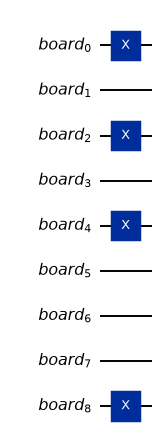

In [3]:
board = CASES["Single win"]
print(show(board), end="\n\n")
board_reg = QuantumRegister(9, "board")
encoder = QuantumCircuit(board_reg)
encode_player_board(encoder, board_reg, board, X)
print("qubits set to |1>:", [encoder.find_bit(i.qubits[0]).index for i in encoder.data])
encoder.draw("mpl", scale=0.7)

## 3. The oracle: flip the sign of winning lines

For each line i, the oracle temporarily flips the line-index qubits so that
index i reads as 111, then applies one multi-controlled Z (MCZ) on 6 qubits:
the 3 line-index qubits and the line's 3 cell qubits. An MCZ flips the *sign*
of the state when all 6 qubits are 1 and does nothing otherwise. Net effect:
every line index the player owns gets a minus sign; nothing else changes.
8 lines, 8 MCZ gates.

Devices have no MCZ gate, so each one is built from a multi-controlled X
(MCX): 5 of the qubits are controls, and the 6th, the line's last cell, is the
target between two H gates (H · X · H = Z). That is the H–MCX–H pattern in the
drawing.

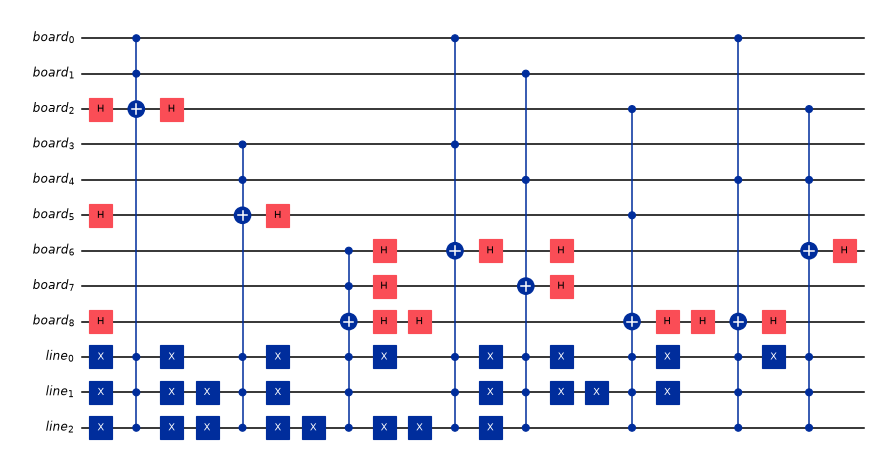

In [4]:
line_reg = QuantumRegister(3, "line")
oracle = QuantumCircuit(board_reg, line_reg)
player_oracle(oracle, board_reg, line_reg)
oracle.draw("mpl", fold=40, scale=0.55)

Checking the effect: start from all 8 indices with equal amplitude, apply the
oracle, and read the sign of each index's amplitude.

In [5]:
qc = QuantumCircuit(board_reg, line_reg)
encode_player_board(qc, board_reg, board, X)
qc.h(line_reg)
qc.compose(oracle, inplace=True)
state = Statevector(qc)
signs = []
for i in range(8):
    # The basis state with this board and line index i.
    index = sum(1 << c for c in range(9) if board[c] == X) | (i << 9)
    signs.append(np.sign(state.data[index].real))
print("winning lines:", sorted(classical_winning_lines(board, X)))
print("sign of each line index after the oracle:", [int(s) for s in signs])

winning lines: [6]
sign of each line index after the oracle: [1, 1, 1, 1, 1, 1, -1, 1]


## 4. The diffuser: turn the sign into probability

A sign alone does not change what is measured. The diffuser reflects every
amplitude about the mean, which boosts the index with the flipped sign and
shrinks the rest.

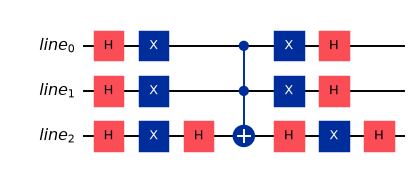

In [6]:
d = QuantumCircuit(line_reg)
diffuser(d, line_reg)
d.draw("mpl", scale=0.7)

The same thing as numbers, read from the statevector of the single-win board
(winning line 6). All 8 indices start at 1/√8 ≈ 0.354. The oracle flips line
6 to −0.354, which pulls the mean of the 8 amplitudes down to 0.265.
Reflecting every amplitude about that mean (new = 2 · mean − old) sends line 6
to 0.884 and every other line to 0.177. Squared: 78% on the winner, 3% on
each of the others. (The circuit's diffuser also multiplies the whole state by
−1. That is a global phase, which changes nothing that can be measured, so the
chart leaves it out.)

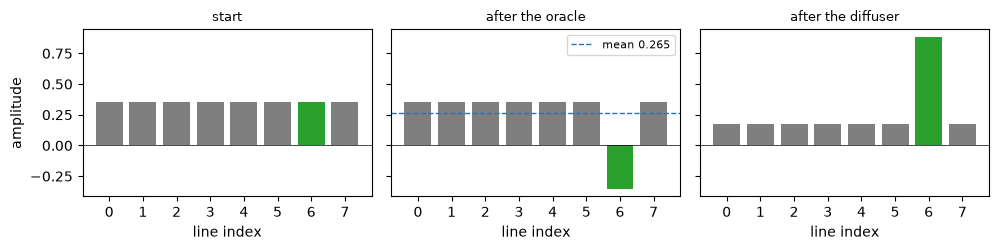

amplitudes after the diffuser: [0.177 0.177 0.177 0.177 0.177 0.177 0.884 0.177]


In [7]:
def line_amplitudes(qc):
    """Amplitude of each line index with this board loaded (the board qubits are in a fixed state)."""
    data = Statevector(qc).data
    base = sum(1 << c for c in range(9) if board[c] == X)
    return np.array([data[base | (i << 9)].real for i in range(8)])


stages = QuantumCircuit(board_reg, line_reg)
encode_player_board(stages, board_reg, board, X)
stages.h(line_reg)
start = line_amplitudes(stages)
stages.compose(oracle, inplace=True)
flipped = line_amplitudes(stages)
diffuser(stages, line_reg)
after = -line_amplitudes(stages)  # undo the diffuser's global phase of -1

fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, amps, title in zip(axes, (start, flipped, after), ("start", "after the oracle", "after the diffuser")):
    ax.bar(range(8), amps, color=["tab:green" if i == 6 else "tab:gray" for i in range(8)])
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_title(title, fontsize=9)
    ax.set_xticks(range(8))
    ax.set_xlabel("line index")
axes[1].axhline(flipped.mean(), color="tab:blue", linestyle="--", linewidth=1, label=f"mean {flipped.mean():.3f}")
axes[1].legend(fontsize=8)
axes[0].set_ylabel("amplitude")
fig.tight_layout()
plt.show()
print("amplitudes after the diffuser:", np.round(after, 3))

## 5. The whole circuit

Load the board, put the line register in an equal superposition, one oracle,
one diffuser, measure the 3 line qubits.

12 qubits, 8 MCX gates (one per MCZ)


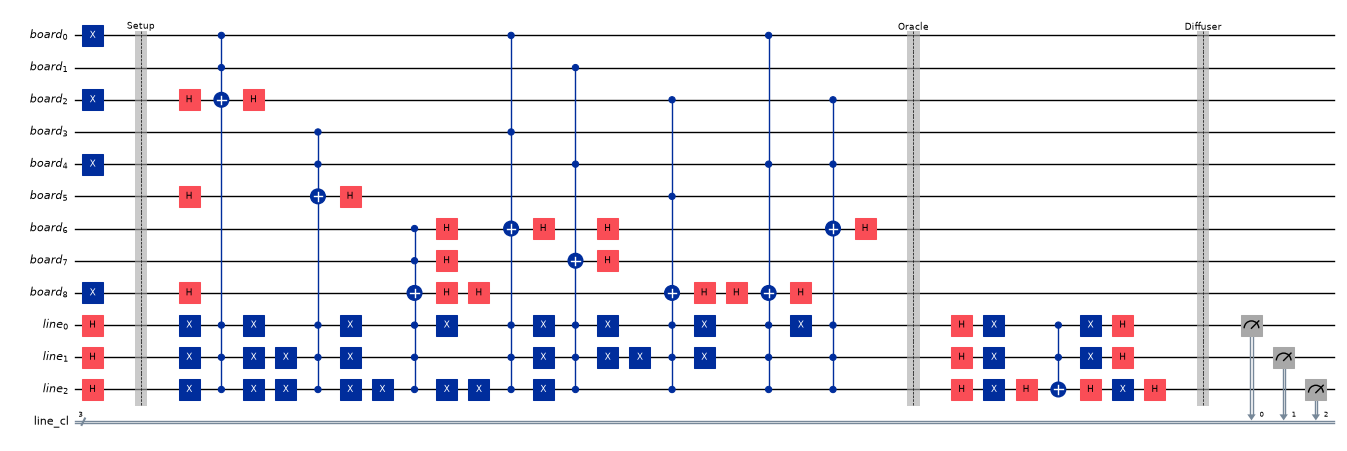

In [8]:
circuit = build_search_circuit("player", board, X)
print(f"{circuit.num_qubits} qubits, {circuit.count_ops().get('mcx', 0)} MCX gates (one per MCZ)")
circuit.draw("mpl", fold=45, scale=0.5)

## 6. Why exactly one Grover iteration

With M of 8 lines marked and sin θ = √(M/8), k iterations put sin²((2k+1)θ) on
the marked lines. A legal board has M = 0, 1 or 2.

iterations  M = 1 (each)  M = 2 (each)
         0         12.5%         12.5%
         1         78.1%         50.0%
         2         94.5%         12.5%
         3         33.0%         12.5%


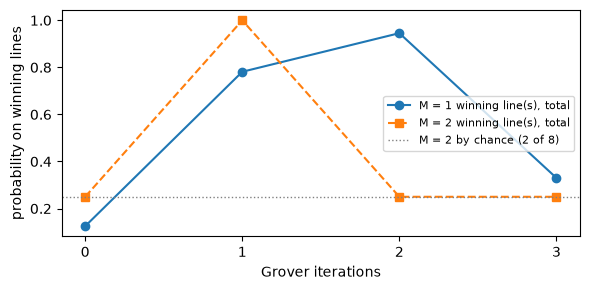

In [9]:
print(f"{'iterations':>10}  {'M = 1 (each)':>12}  {'M = 2 (each)':>12}")
for k in range(4):
    p1 = math.sin((2 * k + 1) * math.asin(math.sqrt(1 / 8))) ** 2
    p2 = math.sin((2 * k + 1) * math.asin(math.sqrt(2 / 8))) ** 2 / 2
    print(f"{k:>10}  {p1:>12.1%}  {p2:>12.1%}")

ks = np.arange(4)  # iterations come in whole numbers
fig, ax = plt.subplots(figsize=(6, 3))
for m, style in ((1, "o-"), (2, "s--")):
    ax.plot(ks, np.sin((2 * ks + 1) * np.arcsin(np.sqrt(m / 8))) ** 2, style, label=f"M = {m} winning line(s), total")
ax.axhline(2 / 8, color="gray", linestyle=":", linewidth=1, label="M = 2 by chance (2 of 8)")
ax.set_xticks(ks)
ax.set_xlabel("Grover iterations")
ax.set_ylabel("probability on winning lines")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Why one iteration is exactly right is easiest to see as a rotation. Split the
state into its part on the winning lines (|good⟩) and the rest (|bad⟩): it is
a unit vector in that 2D plane, starting at angle θ from |bad⟩ with
sin θ = √(M/8). Each Grover iteration (oracle, then diffuser) rotates it by 2θ
toward |good⟩, and the chance of measuring a winner is sin² of the angle.

- M = 1: θ ≈ 20.7°, so one iteration reaches 62° (78%); a second reaches 104°,
  just past |good⟩ (94.5%).
- M = 2: θ = 30°, so one iteration lands exactly on |good⟩ (100%); a second
  overshoots to 150°, back to the starting 25%.
- M = 0: θ = 0; nothing is marked, so nothing rotates.

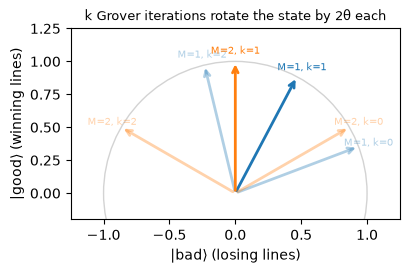

In [10]:
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="lightgray"))
for m, color in ((1, "tab:blue"), (2, "tab:orange")):
    theta = math.asin(math.sqrt(m / 8))
    for k, alpha in ((0, 0.35), (1, 1.0), (2, 0.35)):
        angle = (2 * k + 1) * theta
        ax.annotate("", xy=(math.cos(angle), math.sin(angle)), xytext=(0, 0),
                    arrowprops={"arrowstyle": "->", "color": color, "alpha": alpha, "linewidth": 2})
        ax.text(1.08 * math.cos(angle), 1.08 * math.sin(angle), f"M={m}, k={k}", color=color, alpha=alpha,
                fontsize=7, ha="center", va="center")
ax.set_xlim(-1.25, 1.25)
ax.set_ylim(-0.2, 1.25)
ax.set_aspect("equal")
ax.set_xlabel("|bad⟩ (losing lines)")
ax.set_ylabel("|good⟩ (winning lines)")
ax.set_title("k Grover iterations rotate the state by 2θ each", fontsize=9)
fig.tight_layout()
plt.show()

One iteration separates every case: 78% on a single winner, 50/50 on a
double win, flat 12.5% with no winner. Two iterations push a single winner to
94.5% but send a double win right back to 12.5% everywhere — indistinguishable
from no winner. The class version ran 2 iterations, so it missed double wins.
Reproducing that with the same oracle and diffuser:

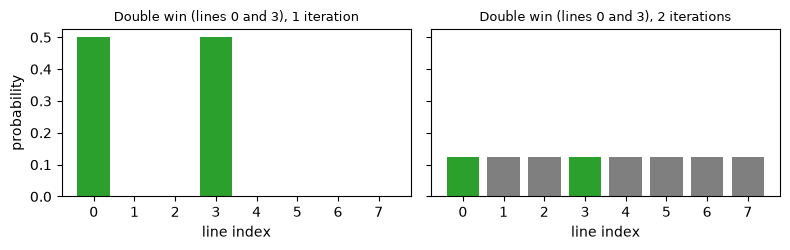

In [11]:
def search(board, player, iterations):
    board_reg = QuantumRegister(9, "board")
    line_reg = QuantumRegister(3, "line")
    qc = QuantumCircuit(board_reg, line_reg, ClassicalRegister(3, "line_cl"))
    encode_player_board(qc, board_reg, board, player)
    qc.h(line_reg)
    for _ in range(iterations):
        player_oracle(qc, board_reg, line_reg)
        diffuser(qc, line_reg)
    return qc


double = CASES["Double win"]
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
for ax, k in zip(axes, (1, 2)):
    probs = line_probabilities(search(double, X, k))
    ax.bar(range(8), probs, color=["tab:green" if i in (0, 3) else "tab:gray" for i in range(8)])
    ax.set_title(f"Double win (lines 0 and 3), {k} iteration{'s' if k > 1 else ''}", fontsize=9)
    ax.set_xticks(range(8))
    ax.set_xlabel("line index")
axes[0].set_ylabel("probability")
fig.tight_layout()
plt.show()

## 7. The three boards on a perfect simulator

Exact probabilities from the statevector, next to the theory.

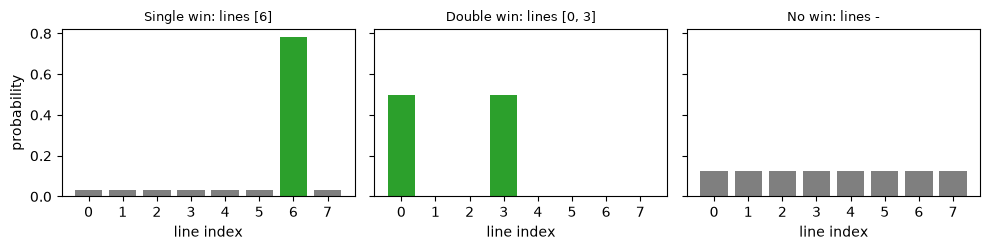

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, (name, board) in zip(axes, CASES.items()):
    winners = classical_winning_lines(board, X)
    probs = line_probabilities(build_search_circuit("player", board, X))
    assert np.allclose(probs, ideal_line_probabilities(winners))
    ax.bar(range(8), probs, color=["tab:green" if i in winners else "tab:gray" for i in range(8)])
    ax.set_title(f"{name}: lines {sorted(winners) or '-'}", fontsize=9)
    ax.set_xticks(range(8))
    ax.set_xlabel("line index")
axes[0].set_ylabel("probability")
fig.tight_layout()
plt.show()

## 8. From counts to a verdict

A real run gives counts, not probabilities: 1024 shots, each landing on one
line index. A line is *flagged* when its count reaches a cutoff, and each
flagged line is checked on the board (3 cell lookups). A confirmed line is
always a real win, so noise can make the detector miss a win but never invent
one.

The cutoff is set by a **check budget**: on a board with no winner each line
gets 1/8 of the shots on average, and the cutoff is the lowest count at which
the expected number of falsely flagged lines per round is at most 0.2: one
extra classical check every five boards. At 1024 shots that is 150 (14.6%).

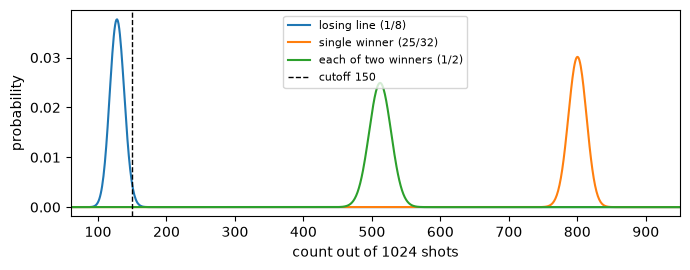

Single win  counts (44, 40, 27, 31, 33, 31, 787, 31)
            flagged [6], confirmed [6], rejected [] -> winner X, classical checks 1
Double win  counts (531, 0, 0, 493, 0, 0, 0, 0)
            flagged [0, 3], confirmed [0, 3], rejected [] -> winner X, classical checks 2


No win      counts (142, 125, 138, 126, 121, 129, 131, 112)
            flagged [], confirmed [], rejected [] -> winner None, classical checks 0


In [13]:
shots = DEFAULT_SHOTS
cutoff = binomial_cutoff(shots, DEFAULT_BUDGET)
ks = np.arange(0, 950)
fig, ax = plt.subplots(figsize=(7, 2.8))
for p, label in ((1 / 8, "losing line (1/8)"), (25 / 32, "single winner (25/32)"), (1 / 2, "each of two winners (1/2)")):
    ax.plot(ks, [binomial_pmf(int(k), shots, p) for k in ks], label=label)
ax.axvline(cutoff, color="black", linestyle="--", linewidth=1, label=f"cutoff {cutoff}")
ax.set_xlim(60, 950)
ax.set_xlabel(f"count out of {shots} shots")
ax.set_ylabel("probability")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for name, board in CASES.items():
    r = detect_winner(board, player=X, shots=shots, backend=IdealBackend(seed=SEED))
    print(f"{name:11} counts {r.run.counts}")
    print(f"{'':11} flagged {list(r.candidates)}, confirmed {sorted(r.lines)}, rejected {list(r.rejected)}"
          f" -> winner {r.winner}, classical checks {r.checks}")

## 9. From 22 qubits to 12

The oracle is the expensive part. A real device has no 6-qubit gate, so the
compiler rewrites every MCX into one- and two-qubit gates and adds swaps to
move qubits next to each other. Two-qubit gates are where most errors happen.

The circuit went through three versions:

- **Class version, 22 qubits:** 2 qubits per cell so X and O can both be
  checked, and the sign flip made by *phase kickback*: an MCX (9 controls)
  whose target is an extra "phase" qubit prepared in |−⟩. Flipping |−⟩ only
  multiplies it by −1, so the minus sign lands on the line index instead.
- **One qubit per cell, 13 qubits:** only the player who just moved is
  checked, so each MCX needs 6 controls, still onto the phase qubit.
- **This version, 12 qubits:** the MCZ flips the sign directly, so the phase
  qubit is gone and each MCX has only 5 controls.

The 13-qubit version is built below in a few lines; it gives exactly the
same probabilities as the 12-qubit one.

In [14]:
def phase_kickback_search(board, player):
    """The 13-qubit version: each line's MCX (6 controls) targets a phase qubit in |->."""
    board_reg = QuantumRegister(9, "board")
    line_reg = QuantumRegister(3, "line")
    phase_reg = QuantumRegister(1, "phase")
    qc = QuantumCircuit(board_reg, line_reg, phase_reg, ClassicalRegister(3, "line_cl"))
    encode_player_board(qc, board_reg, board, player)
    qc.x(phase_reg[0])
    qc.h(phase_reg[0])
    qc.h(line_reg)
    for i, cells in enumerate(WIN_LINES):
        flips = [line_reg[q] for q, bit in enumerate(reversed(line_index_to_bitstring(i))) if bit == "0"]
        if flips:
            qc.x(flips)
        qc.mcx(list(line_reg) + [board_reg[c] for c in cells], phase_reg[0])
        if flips:
            qc.x(flips)
    diffuser(qc, line_reg)
    qc.measure(line_reg, qc.cregs[0])
    qc.metadata = {"exposed_qubits": [9, 10, 11, 12]}  # line and phase qubits, as the package's circuits name them
    return qc


for name, board in CASES.items():
    same = np.allclose(line_probabilities(phase_kickback_search(board, X)),
                       line_probabilities(build_search_circuit("player", board, X)))
    print(f"{name:11} 13-qubit and 12-qubit probabilities equal: {same}")

Single win  13-qubit and 12-qubit probabilities equal: True
Double win  13-qubit and 12-qubit probabilities equal: True
No win      13-qubit and 12-qubit probabilities equal: True


One more trick: a spare qubit that starts in |0⟩ (an *ancilla*) lets each
5-control MCX be built from fewer, shallower pieces (Khattar & Gidney, 2024),
and is returned to |0⟩ afterwards. Each version compiled for `fake_kingston`
(a snapshot of one of the devices on IBM's free plan), 5 compiler seeds, best
kept:

In [15]:
kingston = get_backend("fake_kingston", seed=SEED, transpile_seeds=5)
empty = [EMPTY] * 9
versions = (
    ("class version, 2 qubits per cell", build_search_circuit("full", empty)),
    ("1 qubit per cell, phase qubit", phase_kickback_search(empty, X)),
    ("1 qubit per cell, MCZ", build_search_circuit("player", empty, X)),
    ("  + 1 ancilla", build_search_circuit("player", empty, X, ancilla=True)),
)
print(f"{'version':34} {'qubits':>6} {'2-qubit gates':>14} {'depth':>6} {'ESP':>7} {'idle':>7} {'readout':>8}"
      f" {'score':>7}")
for name, qc in versions:
    m = kingston.metrics(kingston.transpile(qc))
    score = m.log10_esp + m.log10_idle + m.log10_readout
    print(f"{name:34} {qc.num_qubits:>6} {m.two_qubit_gates:>14} {m.depth:>6} {10 ** m.log10_esp:>7.1%}"
          f" {10 ** m.log10_idle:>7.1%} {10 ** m.log10_readout:>8.1%} {10 ** score:>7.1%}")

version                            qubits  2-qubit gates  depth     ESP    idle  readout   score


class version, 2 qubits per cell       22           2702   6402    0.2%    1.6%    97.2%    0.0%


1 qubit per cell, phase qubit          13            738   1772   28.0%   41.3%    95.8%   11.1%


1 qubit per cell, MCZ                  12            481   1588   44.5%   55.8%    95.8%   23.8%


  + 1 ancilla                          13            464    997   45.3%   49.6%    96.8%   21.7%


ESP (estimated success probability) is worked out before anything runs: IBM
publishes a measured error rate for every gate on every qubit (updated with
each calibration), and ESP multiplies (1 − error) over every gate in the
compiled circuit: roughly the chance that no gate fails. The 22-qubit circuit
has essentially no chance; the 12-qubit circuit keeps enough signal to work, as
`02_noise` shows.

ESP leaves out the time qubits spend waiting, which on these devices costs as
much as the gates. So the backend scores each compiled circuit by three
published numbers multiplied together: ESP; *idle*, the chance that the line
qubits (and the ancilla) keep their phase while they wait, from each qubit's
measured T1 and T2; and *readout*, the chance the 3 line qubits are read
correctly. The board qubits only hold 0 or 1, so their waiting does not count.
It compiles the 12-qubit circuit with and without the ancilla, over 5 compiler
seeds each, and keeps the highest score (`ancilla="auto"`, the default). The
pick is not always the circuit with the fewest gates: on this kingston snapshot
the plain circuit has more gates and depth than the ancilla one, but its line
qubits wait less, and in simulation it keeps more of the signal (0.34 of shots
on a single winner against 0.28; `results/noise_bias_score.json`). `02_noise`
shows which one each device gets.

The layout of the device matters too. IBM's current devices connect each qubit
to at most 3 neighbours (a "heavy-hex" grid), while the 120-qubit fake_berlin
and fake_miami snapshots use a square grid where most qubits have 4. With more
neighbours, the 6 qubits of each multi-controlled gate sit closer together and
the compiler needs fewer swaps:

In [16]:
from collections import Counter

berlin = get_backend("fake_berlin", seed=SEED, transpile_seeds=5)
print(f"{'device':14} {'qubits':>6}  {'qubits by number of neighbours':32} {'2-qubit gates':>13}")
for device in (kingston, berlin):
    graph = device.backend.coupling_map.graph.to_undirected(multigraph=False)
    degrees = Counter(graph.degree(q) for q in graph.node_indices())
    m = device.metrics(device.search_template("player"))
    by_degree = ", ".join(f"{d}: {n}" for d, n in sorted(degrees.items()))
    print(f"{device.name:14} {device.backend.num_qubits:>6}  {by_degree:32} {m.two_qubit_gates:>13}")

device         qubits  qubits by number of neighbours   2-qubit gates


fake_kingston     156  1: 8, 2: 100, 3: 48                        481


fake_berlin       120  2: 4, 3: 36, 4: 80                         320


## 10. Why quantum?

Checking all 8 lines classically takes 24 cell lookups and no qubits. This
circuit needs hundreds of noisy two-qubit gates to point at the right line, so
it is not faster or cheaper. Tic-tac-toe has no "hard to find, easy to check"
gap for Grover to exploit, and 8 items is far too few for its √N speedup to
matter.

What it is good for is learning and measuring: the full Grover pipeline
(encoding, oracle, diffuser, measurement, classical verification) on a problem
small enough to check every case, and a clean test of how much signal survives
on today's hardware.

The same goes for the classical-check count in `03_hardware`: the detector
needs well under one classical check per board instead of checking all 8
lines, which sounds like a saving. It is not one, even in principle. The
oracle has one gate per line, so every shot of the circuit evaluates all 8
lines, and each board takes 1024 shots.